# E2 — Horizontal circle (anisotropy)

`e2_circle.py`. e_F is split into its **radial** part (along the centripetal acceleration: the inertia
error) and its **tangential** part (along the motion: friction, which no model has). Expected: M4's radial
e_F oscillates at twice the circle frequency, M5's stays flat. M5 is shown twice: orientation
held (the talk's RIM) and rotation free (the plain arm reduction, which misses the OSC's orientation hold
and is ~7× too light along x). `felt_radial_mean` is the inertia you feel, `robot_radial_mean` the robot's
centripetal force; their difference is the radial e_F.

In [1]:
# Runs to analyse: run directories, session files (exp/<exp>/sessions/*.txt, written by the script) or a
# folder of runs (a folder also holds retried and superseded runs). Default: the latest session file,
# which lists every condition once.
from common import latest_session

RUNS = [latest_session("e2")]
RECOMPUTE = False  # True: recompute the metrics from the data instead of reading analysis/metrics.json

In [2]:
import sys
from pathlib import Path

HERE = Path.cwd()  # experiments/rim-delays/exp
sys.path[:0] = [str(HERE), str(HERE.parent)]
import matplotlib.pyplot as plt  # noqa: I001
import numpy as np
import pandas as pd

import exp_metrics
import plots as P
from common import collect, load_table

%matplotlib inline
pd.set_option("display.precision", 3)

runs = collect(RUNS)
df = load_table(runs, exp_metrics.e2 if RECOMPUTE else None)
print(f"{len(df)} runs")

8 runs


In [3]:
df[
    [
        "run",
        "method",
        "rtt",
        "eF_rms",
        "eF_radial_mean",
        "eF_radial_rms",
        "eF_tangential_mean",
        "eF_tangential_rms",
        "eF_z_rms",
        "felt_radial_mean",
        "robot_radial_mean",
        "angle_f_deg",
        "angle_Fosc_deg",
        "E_end_J",
    ]
].sort_values(["rtt", "method"])

,run,method,rtt,eF_rms,eF_radial_mean,eF_radial_rms,eF_tangential_mean,eF_tangential_rms,eF_z_rms,felt_radial_mean,robot_radial_mean,angle_f_deg,angle_Fosc_deg,E_end_J
2,20261026_143247_e2_proxy-fixed-mass_rtt0,proxy-fixed-mass,0,15.880,3.649,8.156,11.398,12.926,4.309,4.896,8.545,-0.564,-56.819,-28.752
0,20261026_143045_e2_proxy-god-object_rtt0,proxy-god-object,0,17.405,8.321,10.914,11.313,12.816,4.424,0.000,8.321,0.064,-56.938,-28.107
4,20261026_143438_e2_proxy-rim_rtt0_held,proxy-rim,0,14.034,0.770,6.453,11.166,12.104,2.969,8.031,8.801,-2.615,-55.174,-28.650
6,20261026_143645_e2_proxy-rim_rtt0_free,proxy-rim-free,0,16.578,6.957,9.969,11.264,12.805,3.387,1.348,8.306,-1.130,-57.344,-28.082
3,20261026_143339_e2_proxy-fixed-mass_rtt2600,proxy-fixed-mass,2600,15.780,3.592,8.114,11.269,12.793,4.415,4.896,8.488,-0.562,-56.922,-28.862
1,20261026_143145_e2_proxy-god-object_rtt2600,proxy-god-object,2600,17.352,8.225,10.924,11.161,12.731,4.436,0.000,8.225,0.221,-56.948,-28.078
5,20261026_143543_e2_proxy-rim_rtt2600_held,proxy-rim,2600,15.012,0.899,7.387,11.420,12.586,3.520,7.932,8.832,-0.167,-56.085,-29.455
7,20261026_143756_e2_proxy-rim_rtt2600_free,proxy-rim-free,2600,16.601,7.112,10.044,11.174,12.676,3.747,1.331,8.443,0.355,-55.907,-28.227


## e_F against the circle phase
Radial (left) and tangential (right); one row per delay.

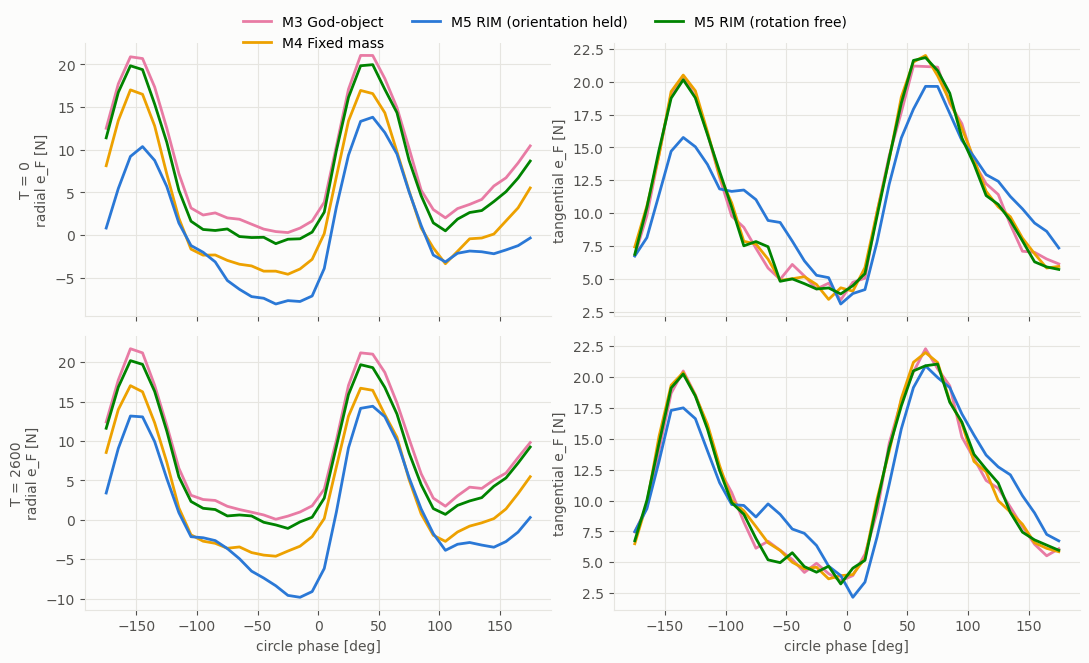

In [4]:
delays = [d for d in P.DELAYS if d in set(df.rtt.map(P.delay_key))]
fig, axes = plt.subplots(len(delays), 2, figsize=(11, 3.2 * len(delays)), squeeze=False, sharex=True)
for i, T in enumerate(delays):
    sub = df[df.rtt.map(P.delay_key) == T]
    for _, row in sub.iterrows():
        m = P.metrics_of(row.dir)
        for j, key in enumerate(("eF_radial_by_phase", "eF_tangential_by_phase")):
            y = np.array([np.nan if v is None else v for v in m[key]])
            axes[i, j].plot(
                m["phase_deg"],
                y,
                color=P.color(row.method),
                label=P.LABELS.get(row.method, row.method) if (i, j) == (0, 0) else None,
            )
    axes[i, 0].set_ylabel(f"T = {T}\nradial e_F [N]")
    axes[i, 1].set_ylabel("tangential e_F [N]")
for ax in axes[-1]:
    ax.set_xlabel("circle phase [deg]")
fig.legend(loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.04))
fig.tight_layout()

## Mean radial and tangential e_F, and the force direction
Angles: from the centripetal direction to the felt force and to the robot's force (0° = parallel).

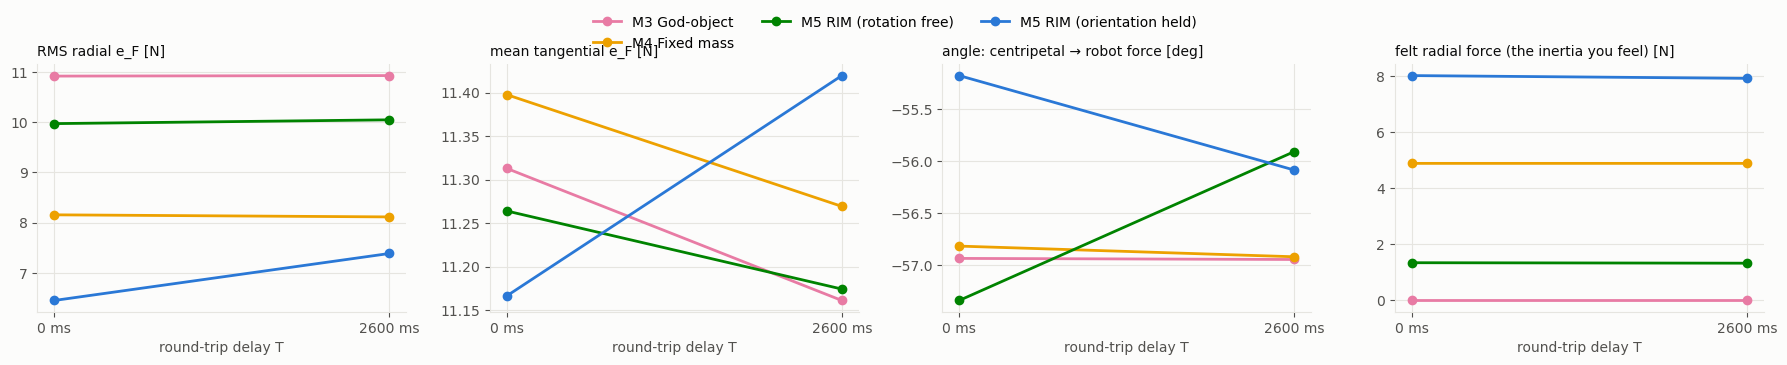

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.4))
for ax, y, title in (
    (axes[0], "eF_radial_rms", "RMS radial e_F [N]"),
    (axes[1], "eF_tangential_mean", "mean tangential e_F [N]"),
):
    P.by_delay(ax, df, y, label_methods=(ax is axes[0]))
    ax.set_title(title, loc="left", fontsize=10)
P.by_delay(axes[2], df, "angle_Fosc_deg", label_methods=False)
axes[2].set_title("angle: centripetal → robot force [deg]", loc="left", fontsize=10)
P.by_delay(axes[3], df, "felt_radial_mean", label_methods=False)
axes[3].set_title("felt radial force (the inertia you feel) [N]", loc="left", fontsize=10)
fig.legend(loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.08))
fig.tight_layout()

## Run checks

Every run should have ended normally, at the frozen OSC stiffness, with M5's reduction as labelled
(held / free) and M4's mass $n^\top\Lambda_0 n$ along +y. `e2_checks` loads every run: besides these,
it bins the felt and robot forces against the circle phase for the sections below.

In [6]:
from runs import load_run

chk = pd.DataFrame([{"run": Path(r).name, **exp_metrics.e2_checks(load_run(r))} for r in runs])
df = df.drop(columns=[c for c in chk.columns if c != "run" and c in df.columns]).merge(chk, on="run")
df[["run", "method", "rtt", "stop_reason", "osc_k_pos_x", "hold_orientation", "proxy_mass", "guard_s"]]

,run,method,rtt,stop_reason,osc_k_pos_x,hold_orientation,proxy_mass,guard_s
0,20261026_143045_e2_proxy-god-object_rtt0,proxy-god-object,0,run ended,2000.0,True,1.000,0.0
1,20261026_143145_e2_proxy-god-object_rtt2600,proxy-god-object,2600,run ended,2000.0,True,1.000,0.0
2,20261026_143247_e2_proxy-fixed-mass_rtt0,proxy-fixed-mass,0,run ended,2000.0,True,4.732,0.0
3,20261026_143339_e2_proxy-fixed-mass_rtt2600,proxy-fixed-mass,2600,run ended,2000.0,True,4.732,0.0
4,20261026_143438_e2_proxy-rim_rtt0_held,proxy-rim,0,run ended,2000.0,True,1.000,0.0
5,20261026_143543_e2_proxy-rim_rtt2600_held,proxy-rim,2600,run ended,2000.0,True,1.000,0.0
6,20261026_143645_e2_proxy-rim_rtt0_free,proxy-rim-free,0,run ended,2000.0,False,1.000,0.0
7,20261026_143756_e2_proxy-rim_rtt2600_free,proxy-rim-free,2600,run ended,2000.0,False,1.000,0.0


## What is rendered: the felt radial force against the phase

On a constant-speed circle the proxy is accelerated inward by $a = r\omega^2$, so the force the operator
should feel is the outward reaction $u^\top\Lambda u\,a$, with $u$ the inward direction. It varies at
twice the circle frequency (2f) when $\Lambda$ is anisotropic in the plane. Dashed: the model at the
circle's centre, with $\Lambda$ orientation held (M5 held), rotation free (M5 free) and M4's $m$. The
felt force has no friction in it, so this is where the models' difference shows cleanly. M5 held's
felt force follows the model's 2f shape about 30° late and peaks unevenly (the proxy follows the leader
through the coupling spring, and $\Lambda$ changes around the circle); its 2f amplitude matches.

,method,rtt,felt_radial_mean,model_mean,felt_radial_2f,model_2f,eF_radial_mean
4,proxy-rim,0,8.031,7.182,2.769,2.452,0.770
2,proxy-fixed-mass,0,4.896,4.670,0.016,0.000,3.649
6,proxy-rim-free,0,1.348,1.406,0.084,0.046,6.957
0,proxy-god-object,0,0.000,0.000,0.000,0.000,8.321
5,proxy-rim,2600,7.932,7.182,3.082,2.452,0.899
3,proxy-fixed-mass,2600,4.896,4.670,0.015,0.000,3.592
7,proxy-rim-free,2600,1.331,1.406,0.050,0.046,7.112
1,proxy-god-object,2600,0.000,0.000,0.000,0.000,8.225


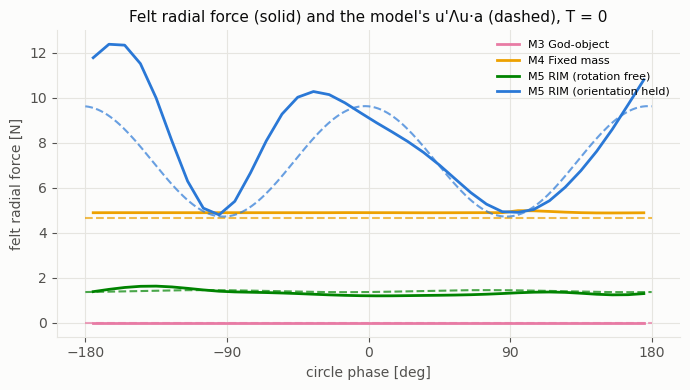

In [7]:
from common import start_inertia

CENTER = [0.5, 0.0, 0.25]  # e2_circle.py: the circle's centre
lam_c = start_inertia(CENTER)
a = float(df.accel.median())
ph = np.radians(np.linspace(-180, 180, 181))
u = -np.c_[np.cos(ph), np.sin(ph)]
model = {
    "proxy-rim": np.einsum("ij,jk,ik->i", u, lam_c["Lambda_held"][:2, :2], u) * a,
    "proxy-rim-free": np.einsum("ij,jk,ik->i", u, lam_c["Lambda"][:2, :2], u) * a,
    "proxy-fixed-mass": np.full_like(ph, df.proxy_mass[df.method == "proxy-fixed-mass"].iloc[0] * a),
    "proxy-god-object": np.zeros_like(ph),
}
t0 = df[df.rtt.map(P.delay_key) == "0"]
fig, ax = plt.subplots(figsize=(7, 4))
for m in P.methods_in(t0):
    row = t0[t0.method == m].iloc[0]
    y = np.array([np.nan if v is None else v for v in row.felt_radial_by_phase])
    ax.plot(row.phase_deg, y, lw=2, color=P.color(m), label=P.LABELS.get(m, m))
    ax.plot(np.degrees(ph), model[m], "--", lw=1.5, color=P.color(m), alpha=0.7)
ax.set(
    xlabel="circle phase [deg]",
    ylabel="felt radial force [N]",
    xticks=range(-180, 181, 90),
    title="Felt radial force (solid) and the model's u'Λu·a (dashed), T = 0",
)
ax.legend(fontsize=8, frameon=False, loc="upper right")
fig.tight_layout()

pred = {m: (y.mean(), (y.max() - y.min()) / 2) for m, y in model.items()}
df.assign(model_mean=df.method.map(lambda m: pred[m][0]), model_2f=df.method.map(lambda m: pred[m][1]))[
    ["method", "rtt", "felt_radial_mean", "model_mean", "felt_radial_2f", "model_2f", "eF_radial_mean"]
].sort_values(["rtt", "eF_radial_mean"])

## The robot side: direction-dependent friction dominates the 2f

The plan expected M4's $e_F$ to oscillate at 2f while M5's stays flat. On the robot, the robot's own
force has a large 2f component in **every** method, so the radial $e_F$ does too. It is not inertia:
at constant speed inertia puts no tangential force on the robot, yet $F_{osc}$ has a tangential mean
(~11 N) and a tangential 2f component in every method. Joint friction mapped to Cartesian space
depends on the direction of motion and is not aligned with the velocity; its radial share bends the
robot's path into an ellipse (radius ±4–5 mm at 2f), which $K_r$ turns into the radial 2f force.
The model's inertial 2f (above, ~2.4 N; ~3.5 N with E1's 1.43× heavier arm) is well below it.
The robot's force is the same in every method: the robot needs the same force whatever the method;
the methods only split it differently between the feedforward and the PD correction.

,method,rtt,eF_radial_rms,robot_radial_mean,robot_radial_2f,robot_tangential_mean,robot_tangential_2f,robot_radius_mean,robot_radius_half_range
2,proxy-fixed-mass,0,8.156,8.545,8.687,11.446,6.845,104.906,4.281
0,proxy-god-object,0,10.914,8.321,8.333,11.313,6.642,102.366,4.210
4,proxy-rim,0,6.453,8.801,8.448,11.604,7.358,106.589,5.550
6,proxy-rim-free,0,9.969,8.306,8.510,11.295,6.840,103.078,4.247
3,proxy-fixed-mass,2600,8.114,8.488,8.712,11.317,6.833,104.878,4.327
1,proxy-god-object,2600,10.924,8.225,8.491,11.161,6.683,102.337,4.294
5,proxy-rim,2600,7.387,8.832,9.067,11.457,7.157,106.564,5.203
7,proxy-rim-free,2600,10.044,8.443,8.443,11.166,6.573,103.136,4.197


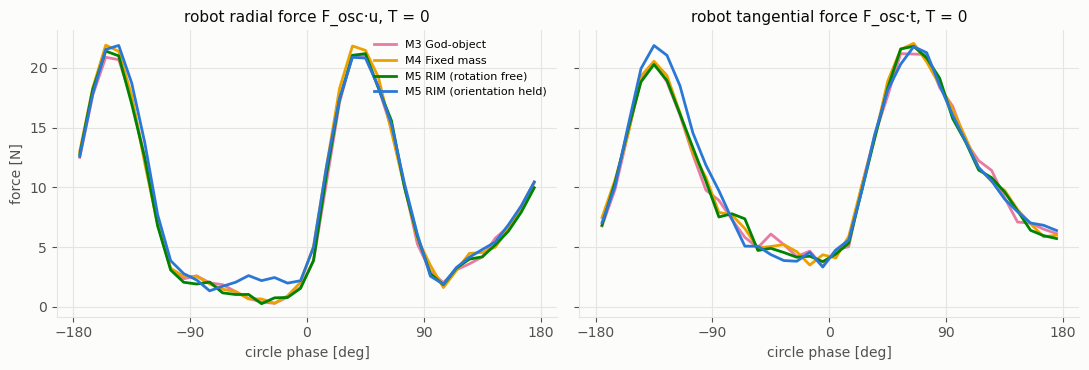

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, key, title in [
    (axes[0], "robot_radial_by_phase", "robot radial force F_osc·u"),
    (axes[1], "robot_tangential_by_phase", "robot tangential force F_osc·t"),
]:
    for m in P.methods_in(t0):
        row = t0[t0.method == m].iloc[0]
        ax.plot(
            row.phase_deg,
            [np.nan if v is None else v for v in row[key]],
            lw=2,
            color=P.color(m),
            label=P.LABELS.get(m, m),
        )
    ax.set(xlabel="circle phase [deg]", xticks=range(-180, 181, 90), title=f"{title}, T = 0")
axes[0].set_ylabel("force [N]")
axes[0].legend(fontsize=8, frameon=False)
fig.tight_layout()

out = df[
    [
        "method",
        "rtt",
        "eF_radial_rms",
        "robot_radial_mean",
        "robot_radial_2f",
        "robot_tangential_mean",
        "robot_tangential_2f",
        "robot_radius_mean",
        "robot_radius_half_range",
    ]
].copy()
out[["robot_radius_mean", "robot_radius_half_range"]] *= 1e3  # [mm]
out.sort_values(["rtt", "method"])

## The force–acceleration angle at this location

The plan's angle plot looks for the sideways component that off-diagonal inertia adds (M5 reproduces
it, M4 cannot). At the circle's centre the held $\Lambda$ is nearly diagonal in the plane, so there is
little to see: the felt force stays within a few degrees of centripetal for every method, and the
robot's force angle is set by friction ($\arctan$ of tangential over radial).

In [9]:
for key in ("Lambda_held", "Lambda"):
    L = lam_c[key][:2, :2]
    w, v = np.linalg.eigh(L)
    print(
        f"{key:12s} xy block: diag {np.diag(L).round(2)} kg, off-diagonal {L[0, 1]:+.2f} kg, eigenvalues {w.round(2)} kg"
    )
df[["method", "rtt", "angle_f_deg", "angle_Fosc_deg"]].assign(
    friction_angle_deg=-np.degrees(np.arctan2(df.robot_tangential_mean, df.robot_radial_mean))
).sort_values(["rtt", "method"])

Lambda_held  xy block: diag [9.74 4.79] kg, off-diagonal -0.20 kg, eigenvalues [4.78 9.75] kg
Lambda       xy block: diag [1.38 1.46] kg, off-diagonal +0.02 kg, eigenvalues [1.38 1.47] kg


,method,rtt,angle_f_deg,angle_Fosc_deg,friction_angle_deg
2,proxy-fixed-mass,0,-0.564,-56.819,-53.257
0,proxy-god-object,0,0.064,-56.938,-53.666
4,proxy-rim,0,-2.615,-55.174,-52.823
6,proxy-rim-free,0,-1.130,-57.344,-53.671
3,proxy-fixed-mass,2600,-0.562,-56.922,-53.130
1,proxy-god-object,2600,0.221,-56.948,-53.613
5,proxy-rim,2600,-0.167,-56.085,-52.374
7,proxy-rim-free,2600,0.355,-55.907,-52.905


## Discussion

Results of the 2026-10-26 session (8 runs, one per condition).

**What holds.**
- Every method is flat in the delay: T = 0 and 2.6 s agree within ~1 N on every metric.
- The mean radial $e_F$, the centripetal force the robot needed and the operator did not feel, orders the
  methods by model fidelity: M3 8.3 N → M5 free 7.0 → M4 3.6 → M5 held 0.8 N.
- The felt force shows the anisotropy: M5 held renders $u^\top\Lambda u\,a$, mean 8.0 N with a 2.8 N
  2f swing (model 7.2 / 2.4 N); M4 is flat at its $m a$ (4.9 N); the free reduction renders only
  1.35 N, ~7× too light (the reason M5 holds the orientation).

**What does not show, and why (unmodelled dynamics).**
- *The 2f oscillation of $e_F$.* It is ~8.5 N in every method, M5 held included, against an inertial
  difference of ~2.4 N. It is joint friction: direction-dependent in Cartesian space, ~11 N tangential
  on this circle, with a 2f component of ~7 N tangential and ~8.5 N radial (through the elliptical
  tracking error). No method models friction, so it lands in every method's $e_F$ alike and hides
  M4's inertial 2f. A faster circle would not help much: the inertial part grows with $a$, friction
  stays about the same, and the joint-velocity limit is already at ~52 %.
- *The force–acceleration angle.* The held $\Lambda$ is nearly diagonal here (off-diagonal −0.2 kg
  against 9.7 and 4.8 kg), so there is no sideways inertial component to reproduce; the robot's
  force angle (~−57°) is friction. Showing the coupling would need a location with a strong x–y
  off-diagonal.
- *Inertia.* The robot's mean centripetal force (8.3–8.8 N) is ~1.2× the held model's, consistent
  with E1's heavier arm (rotor inertia); friction's radial share makes E2 a poor place to measure it.

**For the talk.** The mean radial $e_F$ ladder and the felt radial force against the phase (M5 held
follows $u^\top\Lambda u$, M4 flat) carry the anisotropy message; the 2f residual of $e_F$ goes under
unmodelled dynamics, with E1's friction and inertia findings.